In [14]:
import pandas as pd 
import numpy as np 
import re 
from nltk.stem.porter import PorterStemmer
from sklearn.feature_extraction.text import TfidfVectorizer,CountVectorizer
from sklearn.model_selection import train_test_split
import pickle
import matplotlib.pyplot as plt 
from  nltk.corpus import stopwords
from nltk.stem.lancaster import LancasterStemmer
import string 
import seaborn as sns 


In [17]:
df=pd.read_csv("train.csv")

In [18]:
df.head()

,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0
3,0001b41b1c6bb37e,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0


In [19]:
alphanumeric=lambda x: re.sub('\w\d\w',' ',x)   # aise krke = har ek mai sare functions fit krwa diye then agle code m use column m fit krwa diya simple 
punc_lower=lambda x: re.sub('[%s]'  % re.escape(string.punctuation),' ',x.lower())
remove_n=lambda x : re.sub('\n',' ',x)
remove_non_ascii=lambda x: re.sub('[^\x00-\x7f]',r' ',x)

In [20]:
df['comment_text']=df['comment_text'].map(alphanumeric).map(punc_lower).map(remove_n).map(remove_non_ascii)
df.comment_text.head()

0    explanation why the edits made under my userna...
1    d aww  he matches this background colour i m s...
2    hey man  i m really not trying to edit war  it...
3      more i can t make any real suggestions on im...
4    you  sir  are my hero  any chance you remember...
Name: comment_text, dtype: object

In [21]:
df.toxic.value_counts()

toxic
0    144277
1     15294
Name: count, dtype: int64

In [22]:
df.toxic.value_counts(normalize=True)

toxic
0    0.904156
1    0.095844
Name: proportion, dtype: float64

In [23]:
# extracting data 

In [24]:
pip install wordcloud

  Using cached wordcloud-1.9.6-cp313-cp313-win_amd64.whl.metadata (3.5 kB)
Using cached wordcloud-1.9.6-cp313-cp313-win_amd64.whl (306 kB)
Note: you may need to restart the kernel to use updated packages.


In [25]:
import wordcloud 
from PIL import Image
from wordcloud import WordCloud,STOPWORDS,ImageColorGenerator
from nltk.corpus import stopwords
                      # har ek m usi ke hisab se data ko fix krdia taki aage ke liye use rhe 
df_tox=df.loc[:,['id','comment_text','toxic']]
df_sev=df.loc[:,['id','comment_text','severe_toxic']]
df_obs=df.loc[:,['id','comment_text','obscene']]
df_thr=df.loc[:,['id','comment_text','threat']]
df_ins=df.loc[:,['id','comment_text','insult']]
df_ide=df.loc[:,['id','comment_text','identity_hate']]

In [26]:
# ek function bana lia wordcloud naam se jisse baar baar code na dalna pade isse ek hi baar m ho jayega fir asani se 
def wordcloud(df,label):     # label means the column name 
    subset=df[df[label]==1]  # jo ek baar aaya hai faltu m jyada ka koi sense nhi 
    text=subset.comment_text.values  # sari words isme fill krwa diye kyunki coments se are haina
    wc=WordCloud(background_color='black',max_words=4000)
    wc.generate(' '.join(text)) # text ko fir isme join krwa diya 
    plt.figure(figsize=(20,20))
    plt.subplot(221)
    plt.axis('off')
    plt.title('words frequented in {}'.format(label),fontsize=20)  # title m harv ek krke sare column ske naam dedega ye 
    plt.imshow(wc.recolor(colormap='gist_earth',random_state=244),alpha=0.98)


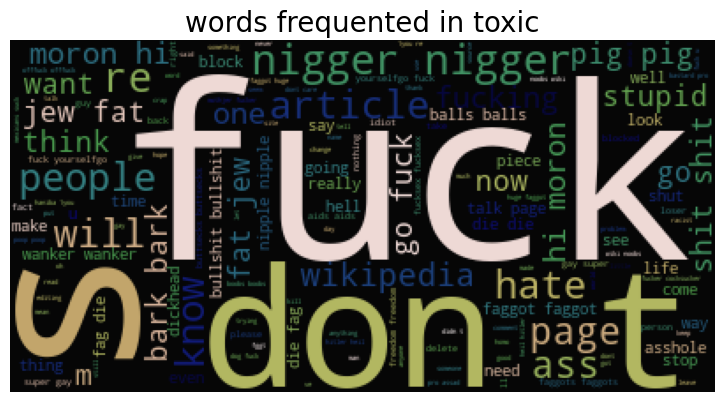

In [27]:
wordcloud(df_tox,'toxic')

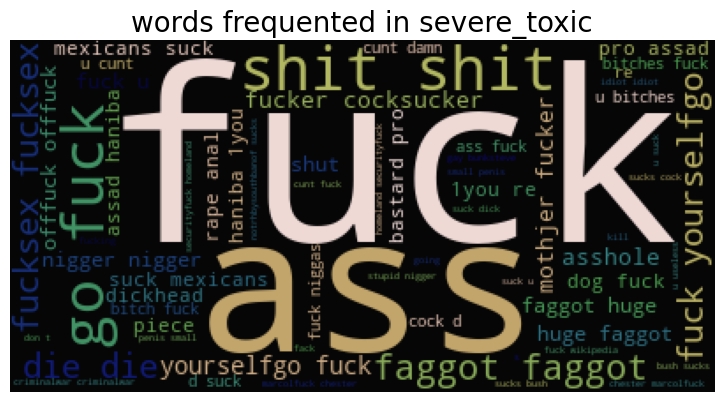

In [28]:
wordcloud(df_sev,'severe_toxic')

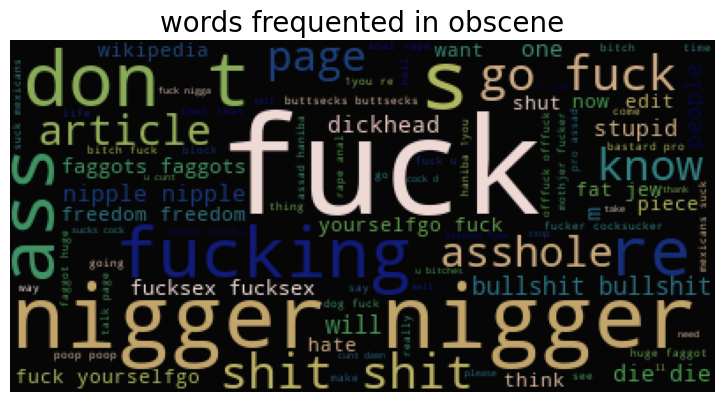

In [29]:
wordcloud(df_obs,'obscene')

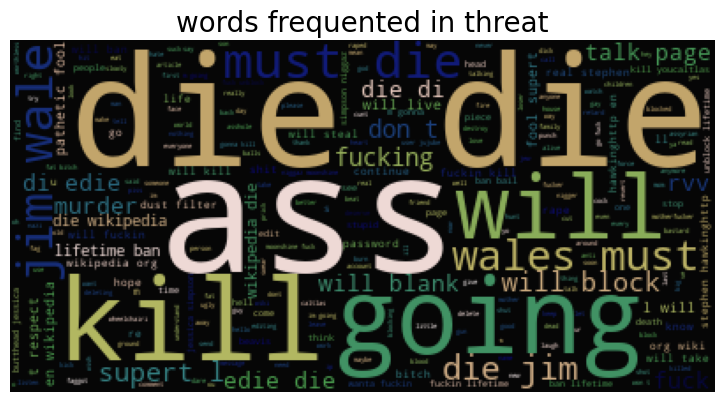

In [30]:
wordcloud(df_thr,'threat')

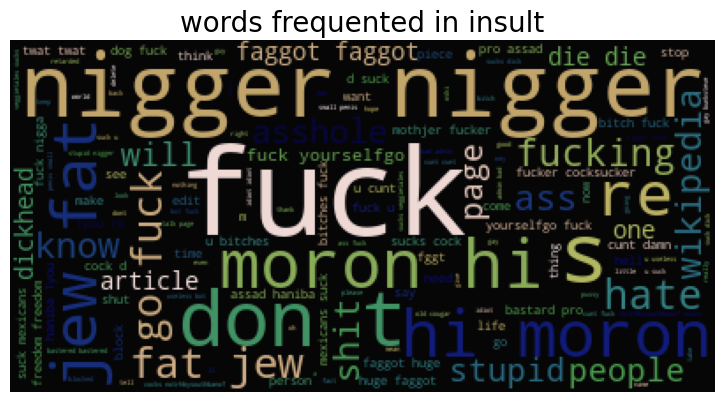

In [31]:
wordcloud(df_ins,'insult')

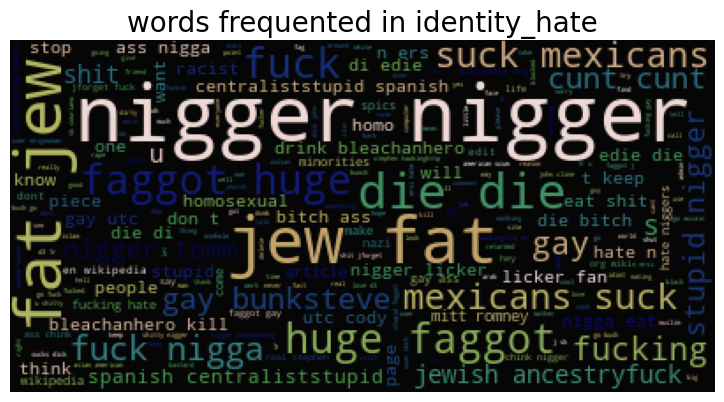

In [32]:
wordcloud(df_ide,'identity_hate')

In [33]:
df.toxic.value_counts()

toxic
0    144277
1     15294
Name: count, dtype: int64

In [34]:
# now there is aproblem
# imbalancing 
df_toxic=df_tox[df_tox['toxic']==1].iloc[:5000,:]   # 1 wale se 5k nikal liye 
df_nontoxic=df_tox[df_tox['toxic']==0].iloc[:5000,:]  # 0 wale se 5k nikal liye 
df_Toxic=pd.concat([df_nontoxic,df_toxic],axis=0)
df_Toxic.shape

(10000, 3)

In [35]:
def wordcloud(df,text):
    label=df[df[text]==1]
    dan=label.comment_text.values
    wc=WordCloud(background_color='black',max_words=5000)
    wc.generate(''.join(dan))
    plt.figure(figsize=(20,20))
    plt.subplot(221)
    plt.title('words existed in the {}'.format(text),fontsize=20)
    plt.imshow(wc.recolor(colormap='gist_earth',random_state=244),alpha=0.98)

    

In [36]:
# ek function bana lia wordcloud naam se jisse baar baar code na dalna pade isse ek hi baar m ho jayega fir asani se 
def wordcloud(df,label):     # label means the column name 
    subset=df[df[label]==1]  # jo ek baar aaya hai faltu m jyada ka koi sense nhi 
    text=subset.comment_text.values  # sari words isme fill krwa diye kyunki coments se are haina
    wc=WordCloud(background_color='black',max_words=4000)
    wc.generate(' '.join(text)) # text ko fir isme join krwa diya 
    plt.figure(figsize=(20,20))
    plt.subplot(221)
    plt.axis('off')
    plt.title('words frequented in {}'.format(label),fontsize=20)  # title m harv ek krke sare column ske naam dedega ye 
    plt.imshow(wc.recolor(colormap='gist_earth',random_state=244),alpha=0.98)


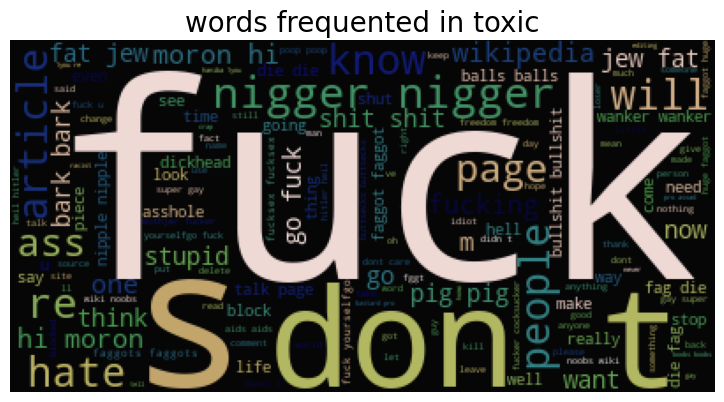

In [37]:
wordcloud(df_tox,'toxic')

In [38]:
def printer(df,comment):
    subset=df[df[comment]==1]
    label=subset.comment_text.values
    wc=WordCloud(background_color='black',max_words=4000)
    wc.generate(' '.join(label))
    plt.subplot(221)
    plt.axis('off')
    plt.figure(figsize=(20,20))
    plt.title('words exist  in {}'.format(comment),fontsize=20)
    plt.imshow(wc.recolor(colormap='gist_earth',random_state=244),alpha=0.98)


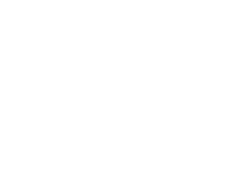

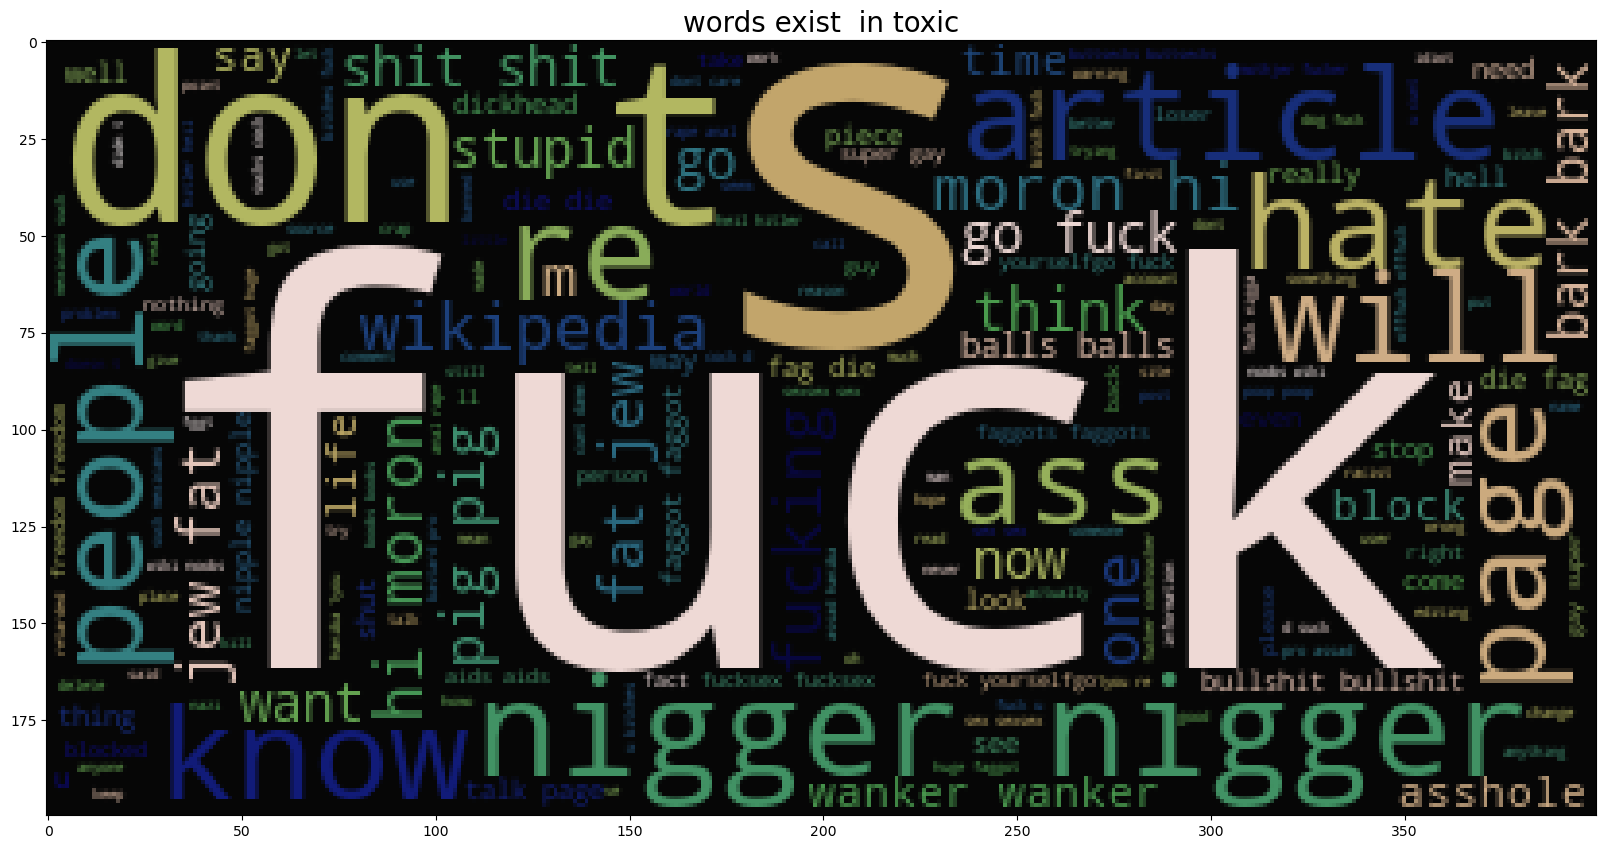

In [39]:
printer(df_tox,'toxic')

In [40]:



df_issev=df_sev[df_sev['severe_toxic']==1].iloc[0:1595,:]
df_nonsev=df_sev[df_sev['severe_toxic']==0].iloc[0:1595,:]
df_SEVERE=pd.concat([df_issev,df_nonsev],axis=0)
df_SEVERE.shape

(3190, 3)

In [41]:
df.obscene.value_counts()

obscene
0    151122
1      8449
Name: count, dtype: int64

In [42]:
df_isobs=df_obs[df_obs['obscene']==1].iloc[0:5000,:]
df_nonobs=df_obs[df_obs['obscene']==0].iloc[0:5000,:]
df_Obscene=pd.concat([df_isobs,df_nonobs],axis=0)
df_Obscene.shape

(10000, 3)

In [43]:
df_isthr=df_thr[df_thr['threat']==1].iloc[0:478,:]
df_nonthr=df_thr[df_thr['threat']==0].iloc[0:1912,:]
df_Threat=pd.concat([df_isthr,df_nonthr],axis=0)
df_Threat.shape

(2390, 3)

In [44]:
df_isins=df_ins[df_ins['insult']==1].iloc[0:5000,:]
df_nonins=df_ins[df_ins['insult']==0].iloc[0:5000,:]
df_Insert=pd.concat([df_isins,df_nonins],axis=0)
df_Insert.shape

(10000, 3)

In [45]:
df_isiden=df_ide[df_ide['identity_hate']==1].iloc[0:1405,:]
df_nonisen=df_ide[df_ide['identity_hate']==0].iloc[0:5620,:]
df_Iden=pd.concat([df_isiden,df_nonisen])
df_Iden.shape

(7025, 3)

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report,f1_score,precision_score,recall_score

In [ ]:
def model_train(data_toxicFeat,label,vectorizer,ngram): #  function bana rhe h bs with variables data toxic feat  
    X=data_toxicFeat.comment_text  # konsa data aayega abhi insert krenge 
    y=data_toxicFeat[label]           # data ka target column  ( alag alag na checck krna pade isloiye ye function bana dia )
    X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.3,random_state=42)
    vect=vectorizer(ngram_range=(ngram),stop_words="english")
    X_train_vect=vect.fit_transform(X_train)
    X_test_vect=vect.transform(X_test)
    lr=LogisticRegression()
    lr.fit(X_train_vect,y_train)
    print("Logistic Regression Done")
    knn=KNeighborsClassifier(n_neighbors=5)
    knn.fit(X_train_vect,y_train)
    print("KNearestNeighbours Done")
    svm_model=LinearSVC()
    svm_model.fit(X_train_vect,y_train)
    print("SupportVectorClassifier done")

    randomforest=RandomForestClassifier(n_estimators=100,random_state=42)
    randomforest.fit(X_train_vect,y_train)
    print("RandomForest done")
   # fir ek ek krke sabko alag run krwana 
    f1_score_data={'F1 Score ({})'.format(label):
    [f1_score(lr.predict(X_test_vect),y_test),
    f1_score(knn.predict(X_test_vect),y_test),
    f1_score(svm_model.predict(X_test_vect),y_test),
    f1_score(randomforest.predict(X_test_vect),y_test)   ]}

    precision_score_data={'Precision Score ({})'.format(label):
    [precision_score(lr.predict(X_test_vect),y_test),
    precision_score(knn.predict(X_test_vect),y_test),
    precision_score(svm_model.predict(X_test_vect),y_test),
    precision_score(randomforest.predict(X_test_vect),y_test)]}

    recall_score_data={'recall Score ({})'.format(label):
    [recall_score(lr.predict(X_test_vect),y_test),
    recall_score(knn.predict(X_test_vect),y_test),
    recall_score(svm_model.predict(X_test_vect),y_test),
    recall_score(randomforest.predict(X_test_vect),y_test)]}

    data_f1=pd.DataFrame(f1_score_data,index=["Log Regression","KNN","SVM","Random Forest"])
    data_precision=pd.DataFrame(precision_score_data,index=["Log Regression","KNN","SVM","Random Forest"])
    data_recall=pd.DataFrame(recall_score_data,index=["Log Regression","KNN","SVM","Random Forest"])

    return data_f1,data_precision,data_recall

In [ ]:
df_tox=model_train(df_Toxic,'toxic',TfidfVectorizer,(1,1))   #  (data,taregt column, vectorizer,(n,gram- means ki words ke pair banana )

In [ ]:
df_tox

In [ ]:
df_Sev=model_train(df_sev,'severe_toxic',TfidfVectorizer,(1,1))   #  (data,taregt column, vectorizer,(n,gram- means ki words ke pair banana )

In [ ]:
df_Sev

In [ ]:
df_Iden=model_train(df_ide,'identity_hate',TfidfVectorizer,(1,1))

In [ ]:
df_Iden

In [ ]:
df_threat=model_train(df_thr,'threat',TfidfVectorizer,(1,1))

In [ ]:
df_threat

In [ ]:
df_ins=(df_ins,'insult',TfidfVectorizer,(1,1))

In [ ]:
df_ins

In [ ]:
f1_all=pd.concat([df_tox[0],df_sev[0],df_obs[0],df_ins[0],df_thr[0],df_ide[0]],axis=1)

In [ ]:
f1_all_trp=f1_all.transpose()
f1_all_trp

In [ ]:
Precision_all=pd.concat([df_tox[1],df_sev[1],df_obs[1],df_ins[1],df_thr[1],df_ide[1]],axis=1)

In [ ]:
Precision_all_trp=Precision_all.transpose()
Precision_all_trp

In [ ]:
Recall_all=pd.concat([df_tox[2],df_sev[2],df_obs[2],df_ins[2],df_thr[2],df_ide[2]],axis=1)
Recall_all_trp=Recall_all.transpose()
Recall_all_trp

In [ ]:
db_toxic=data.loc[:,["comment_text","toxic"]]
db_toxic.sample(10)

In [ ]:
db_Toxic=db_toxic[db_toxic["toxic"]==1].iloc[0:15000,:]
db_nonToxic=db_toxic[db_toxic["toxic"]==0].iloc[0:15000,:]
toxic_dataset=pd.concat([db_Toxic,db_nonToxic],axis=0)
toxic_dataset.shape

In [ ]:
from sklearn.pipeline import Pipeline
X=toxic_dataset["comment_text"]
y=toxic_dataset["toxic"]
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.3,random_state=42)

In [ ]:
steps=[("vectorizer",TfidfVectorizer(ngram_range=(1,1),stop_words="english")),('randomforest',RandomForestClassifier(n_estimators=100,random_state=42))]

In [ ]:
pipe.fit(X_train,y_train)
y_pred=pipe.predict(X_test)
y_pred

In [ ]:
text="save you"
y=pipe.predict([text])
y[0]